# Global Air Quality: Cleaning + Complete EDA

This notebook performs end-to-end analysis on `globalAirQuality.csv` without modifying the original CSV file.

## Step 1: Imports and setup
Load required libraries and set plotting style.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
base = Path(r'D:\\sannidh\\Data Science\\Numpy')
csv_path = base / 'globalAirQuality.csv'
plot_dir = base / 'globalAirQuality_eda_plots'
plot_dir.mkdir(exist_ok=True)

## Step 2: Load data and inspect basic structure

In [2]:
df = pd.read_csv(csv_path)
print('Shape:', df.shape)
display(df.head())
display(df.dtypes)

Shape: (18000, 15)


,timestamp,country,city,latitude,longitude,pm25,pm10,no2,so2,o3,co,aqi,temperature,humidity,wind_speed
0,2025-11-04 18:25:17.554219,US,New York,40.713,-74.006,50.295,108.938,27.998,6.539,52.568,1.096,108,18.504,70.168,3.725
1,2025-11-04 19:25:17.554219,US,New York,40.713,-74.006,32.083,63.043,36.120,4.021,43.536,1.075,90,5.838,80.088,8.969
2,2025-11-04 20:25:17.554219,US,New York,40.713,-74.006,42.250,82.553,26.935,9.538,23.320,0.977,84,31.833,62.783,9.650
3,2025-11-04 21:25:17.554219,US,New York,40.713,-74.006,30.403,79.951,63.536,7.609,31.369,0.230,158,23.140,89.153,8.956
4,2025-11-04 22:25:17.554219,US,New York,40.713,-74.006,21.083,66.423,38.997,6.919,45.615,1.085,97,13.632,76.499,4.017


timestamp       object
country         object
city            object
latitude       float64
longitude      float64
pm25           float64
pm10           float64
no2            float64
so2            float64
o3             float64
co             float64
aqi              int64
temperature    float64
humidity       float64
wind_speed     float64
dtype: object

## Step 3: Missing-value cleaning strategy
- Parse timestamp as datetime
- Fill numeric nulls with median
- Fill categorical nulls with mode
- Fill datetime nulls using forward/back fill

All cleaning is done on a copy (`work`) so the original CSV remains unchanged.

In [3]:
work = df.copy()
work['timestamp'] = pd.to_datetime(work['timestamp'], errors='coerce')

num_cols = work.select_dtypes(include='number').columns.tolist()
cat_cols = work.select_dtypes(include='object').columns.tolist()

for c in num_cols:
    if work[c].isna().any():
        work[c] = work[c].fillna(work[c].median())

for c in cat_cols:
    if work[c].isna().any():
        mode = work[c].mode(dropna=True)
        if not mode.empty:
            work[c] = work[c].fillna(mode.iloc[0])

if work['timestamp'].isna().any():
    work['timestamp'] = work['timestamp'].ffill().bfill()

print('Total missing after cleaning:', int(work.isna().sum().sum()))

Total missing after cleaning: 0


## Step 4: Missing-values plot

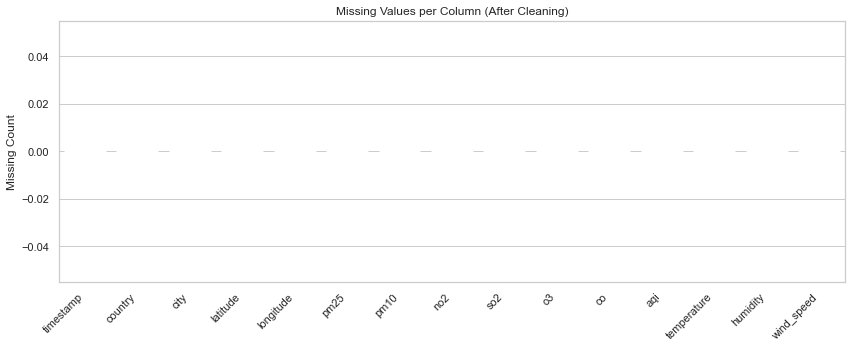

In [4]:
missing = work.isna().sum().sort_values(ascending=False)
plt.figure(figsize=(12,5))
sns.barplot(x=missing.index, y=missing.values, color='#4C72B0')
plt.xticks(rotation=45, ha='right')
plt.title('Missing Values per Column (After Cleaning)')
plt.ylabel('Missing Count')
plt.tight_layout()
plt.savefig(plot_dir / '01_missing_values_bar.png', dpi=150)
plt.show()

## Step 5: Univariate distributions (numeric features)

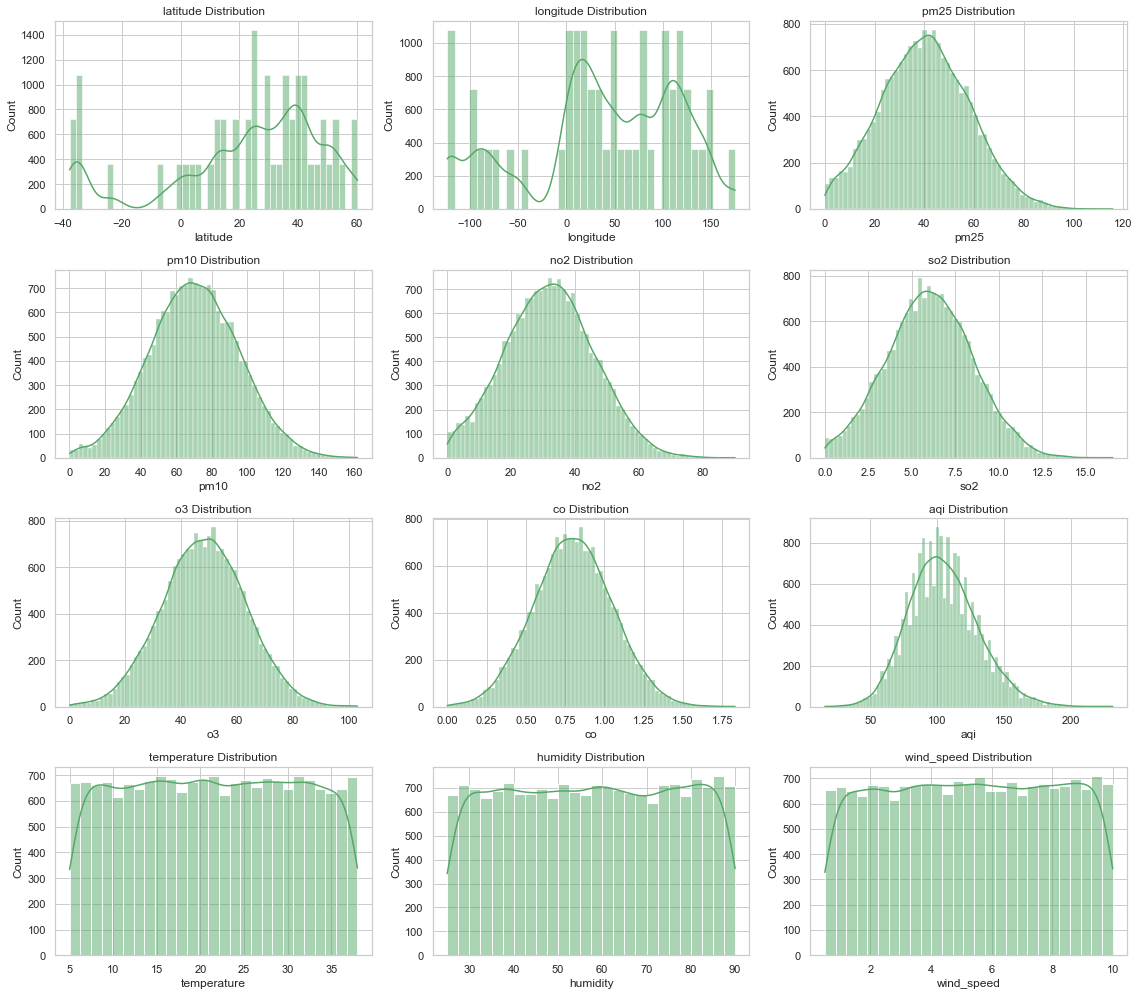

In [5]:
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(work[col], kde=True, ax=axes[i], color='#55A868')
    axes[i].set_title(f'{col} Distribution')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.savefig(plot_dir / '02_numeric_distributions.png', dpi=150)
plt.show()

## Step 6: Boxplots for pollutants and AQI

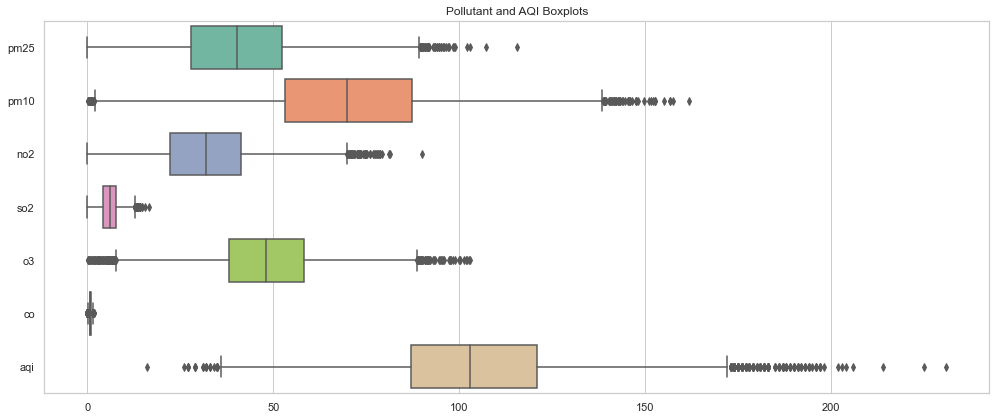

In [6]:
pollutants = ['pm25', 'pm10', 'no2', 'so2', 'o3', 'co', 'aqi']
plt.figure(figsize=(14,6))
sns.boxplot(data=work[pollutants], orient='h', palette='Set2')
plt.title('Pollutant and AQI Boxplots')
plt.tight_layout()
plt.savefig(plot_dir / '03_pollutant_boxplots.png', dpi=150)
plt.show()

## Step 7: Correlation heatmap

In [7]:
corr_cols = ['pm25', 'pm10', 'no2', 'so2', 'o3', 'co', 'temperature', 'humidity', 'wind_speed', 'aqi']
plt.figure(figsize=(10,8))
sns.heatmap(work[corr_cols].corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig(plot_dir / '04_correlation_heatmap.png', dpi=150)
plt.show()

TypeError: corr() got an unexpected keyword argument 'numeric_only'

<Figure size 720x576 with 0 Axes>

## Step 8: AQI category distribution

In [ ]:
bins = [0, 50, 100, 150, 200, 300, 500]
labels = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
work['aqi_category'] = pd.cut(work['aqi'], bins=bins, labels=labels, include_lowest=True)

plt.figure(figsize=(10,5))
order = work['aqi_category'].value_counts().index
sns.countplot(data=work, x='aqi_category', order=order, palette='viridis')
plt.xticks(rotation=25, ha='right')
plt.title('AQI Category Distribution')
plt.tight_layout()
plt.savefig(plot_dir / '05_aqi_category_distribution.png', dpi=150)
plt.show()

## Step 9: Top 10 cities and countries by mean AQI

In [ ]:
top_cities = work.groupby('city', as_index=False)['aqi'].mean().sort_values('aqi', ascending=False).head(10)
top_countries = work.groupby('country', as_index=False)['aqi'].mean().sort_values('aqi', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16,6))
sns.barplot(data=top_cities, x='aqi', y='city', palette='Reds_r', ax=axes[0])
axes[0].set_title('Top 10 Cities by Mean AQI')
sns.barplot(data=top_countries, x='aqi', y='country', palette='Oranges_r', ax=axes[1])
axes[1].set_title('Top 10 Countries by Mean AQI')
plt.tight_layout()
plt.savefig(plot_dir / '06_07_top_locations_aqi.png', dpi=150)
plt.show()

## Step 10: Temporal patterns (hourly and daily AQI)

In [ ]:
work['hour'] = work['timestamp'].dt.hour
hourly = work.groupby('hour', as_index=False)['aqi'].mean()
work['date'] = work['timestamp'].dt.date
daily = work.groupby('date', as_index=False)['aqi'].mean()

fig, axes = plt.subplots(2, 1, figsize=(12,10))
sns.lineplot(data=hourly, x='hour', y='aqi', marker='o', color='#C44E52', ax=axes[0])
axes[0].set_title('Average AQI by Hour')
axes[0].set_xticks(range(0,24,1))
sns.lineplot(data=daily, x='date', y='aqi', marker='o', color='#8172B3', ax=axes[1])
axes[1].set_title('Average AQI by Date')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(plot_dir / '08_09_temporal_aqi_trends.png', dpi=150)
plt.show()

## Step 11: Pollutant relationships with AQI

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, c in zip(axes, ['pm25','pm10','no2']):
    sns.regplot(data=work, x=c, y='aqi', scatter_kws={'alpha':0.25, 's':20}, line_kws={'color':'red'}, ax=ax)
    ax.set_title(f'{c.upper()} vs AQI')
plt.tight_layout()
plt.savefig(plot_dir / '10_11_12_pollutants_vs_aqi.png', dpi=150)
plt.show()

## Step 12: Final summary tables
Show key descriptive statistics and AQI category counts.

In [ ]:
display(work.describe(include='all').T)
display(work['aqi_category'].value_counts(dropna=False))